# ДЗ 1

In [1]:
import sys
from pathlib import Path

# из корня или из папки 1
work = Path.cwd() if Path("analysis.py").exists() else Path.cwd() / "1"
sys.path.insert(0, str(work))

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from analysis import (
    aggregate_sales,
    data_summary,
    decompose,
    describe_series,
    difference,
    iqr_outliers,
    load_data,
    make_calendar,
    plot_aggregations,
    plot_components,
    plot_quality,
    plot_rolling,
    plot_seasonality,
    plot_weekday_and_spectrum,
    save_series,
    select_product,
    stationarity,
    weekday_profile,
)
from IPython.display import display

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.max_columns", 12)
STOCK_CODE = "20725"

## Данные

Товар 20725, продажи в штуках по всем странам без вычитания возвратов

Товар возьмём по StockCode, дату из InvoiceDate, продажи из Quantity.
InvoiceNo с C это отмена, UnitPrice нужен чтобы убрать бесплатные и служебные записи.
Названия бывают разные поэтому отбор по коду

In [3]:
data = load_data(work / "data/Online Retail.xlsx")
display(data.head())
display(data_summary(data))
print("Размер:", data.shape)
print("Период:", data.InvoiceDate.min(), "—", data.InvoiceDate.max())
print("Полных повторов во всём файле:", data.duplicated().sum())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


,тип,пропуски,уникальные
InvoiceNo,str,0,25900
StockCode,str,0,4070
Description,object,1454,4223
Quantity,int64,0,722
InvoiceDate,datetime64[us],0,23260
UnitPrice,float64,0,1630
CustomerID,float64,135080,4372
Country,str,0,38


Размер: (541909, 8)
Период: 2010-12-01 08:26:00 — 2011-12-09 12:50:00
Полных повторов во всём файле: 5268


In [4]:
product, sales, cleaning = select_product(data, STOCK_CODE)
display(product.Description.value_counts().rename("строк"))
display(cleaning.to_frame("значение"))
display(product.isna().sum().rename("пропуски у товара").to_frame())

Description
LUNCH BAG RED RETROSPOT    1638
LUNCH BAG RED SPOTTY          1
Name: строк, dtype: int64

,значение
Строк товара,1639
Точных повторов,13
"Количество в повторах, шт.",121
"Отмен и возвратов, строк",44
"Отмен и возвратов, шт.",574
Прочих исключённых строк,0
Оставлено строк,1582
"Продано за весь файл, шт.",19432


,пропуски у товара
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,280
Country,0


В нужных полях пропусков нет, пустой CustomerID тут не мешает.
Точные повторы примем за дубли и уберём вместе с отменами и возвратами.
Будем считать положительные продажи, возвраты из них вычитать не будем

## Даты

Проверим дни без товара и дни когда во всём магазине нет записей

In [5]:
calendar = make_calendar(data, sales)
display(calendar.status.value_counts().rename("дней").to_frame())
empty_store = calendar.loc[calendar.transactions.eq(0)]
print("Суббот без операций:", (empty_store.index.day_of_week == 5).sum())
print("Остальные даты без операций:")
print(", ".join(empty_store.index[empty_store.index.day_of_week != 5].strftime("%Y-%m-%d")))
print("Дни без продаж товара при работающем магазине:")
print(", ".join(calendar.index[calendar.status.eq("Есть операции магазина, нет продаж товара")].strftime("%Y-%m-%d")))

,дней
status,
Есть продажи товара,298
Нет операций магазина,69
"Есть операции магазина, нет продаж товара",7


Суббот без операций: 53
Остальные даты без операций:
2010-12-24, 2010-12-26, 2010-12-27, 2010-12-28, 2010-12-29, 2010-12-30, 2010-12-31, 2011-01-02, 2011-01-03, 2011-04-22, 2011-04-24, 2011-04-25, 2011-04-29, 2011-05-02, 2011-05-30, 2011-08-29
Дни без продаж товара при работающем магазине:
2011-01-21, 2011-01-23, 2011-01-30, 2011-02-06, 2011-03-13, 2011-03-27, 2011-10-02


По календарю видны пустые субботы и отдельные перерывы.
Примем их за дни без продаж и заполним нулями

Последний день обрывается в середине дня, его уберём. Недели с пн по вс.
Неполные недели и месяцы покажем на графике, в статистики и тесты не возьмём

,всего периодов,полных,NaN в полных,"сумма, шт."
День,373.0,373.0,0.0,19390.0
Неделя,54.0,52.0,0.0,18950.0
Месяц,13.0,12.0,0.0,19035.0


units  days  complete
       date                             
Неделя 2010-12-05  218.0     5     False
       2011-12-11  222.0     4     False
Месяц  2011-12-01  355.0     8     False

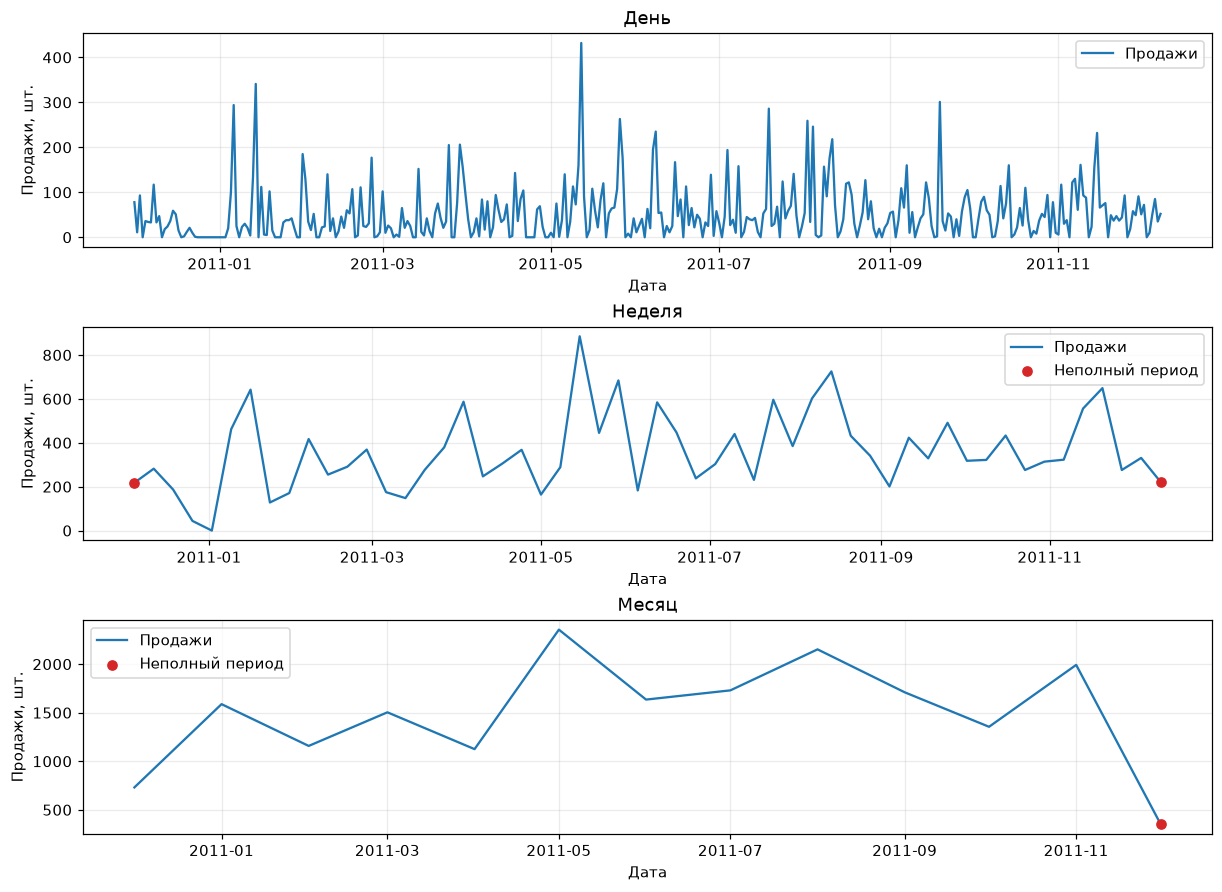

In [6]:
daily = calendar.units.fillna(0).iloc[:-1].rename("units")
aggregated = aggregate_sales(daily)
series = {name: frame.loc[frame.complete, "units"] for name, frame in aggregated.items()}
display(
    pd.DataFrame(
        {
            name: {
                "всего периодов": len(frame),
                "полных": int(frame.complete.sum()),
                "NaN в полных": int(series[name].isna().sum()),
                "сумма, шт.": series[name].sum(),
            }
            for name, frame in aggregated.items()
        }
    ).T
)
display(pd.concat({name: frame.loc[~frame.complete] for name, frame in aggregated.items()}))
plot_aggregations(aggregated)
plt.show()

Получилось 373 дня, 52 полные недели и 12 месяцев, NaN нет.
Суммы разные из-за границ периода. На неделях меньше скачков, месяцев просто мало

## Выбросы

Границы Q1 - 1.5 IQR и Q3 + 1.5 IQR, отдельно для каждой частоты.
Отметим подозрительные точки, не будем считать их сразу ошибками. Рост уровня тоже может попасть за границу

,День
date,
2011-01-06,294.0
2011-01-14,341.0
2011-01-31,185.0
2011-02-25,177.0
2011-03-25,205.0
2011-03-29,206.0
2011-05-12,432.0
2011-05-26,263.0
2011-05-27,176.0


,Неделя
date,
2011-05-15,885.0


,нижняя граница,верхняя граница,отмечено
частота,,,
День,-91.500,168.500,19
Неделя,-35.750,734.250,1
Месяц,571.125,2530.125,0


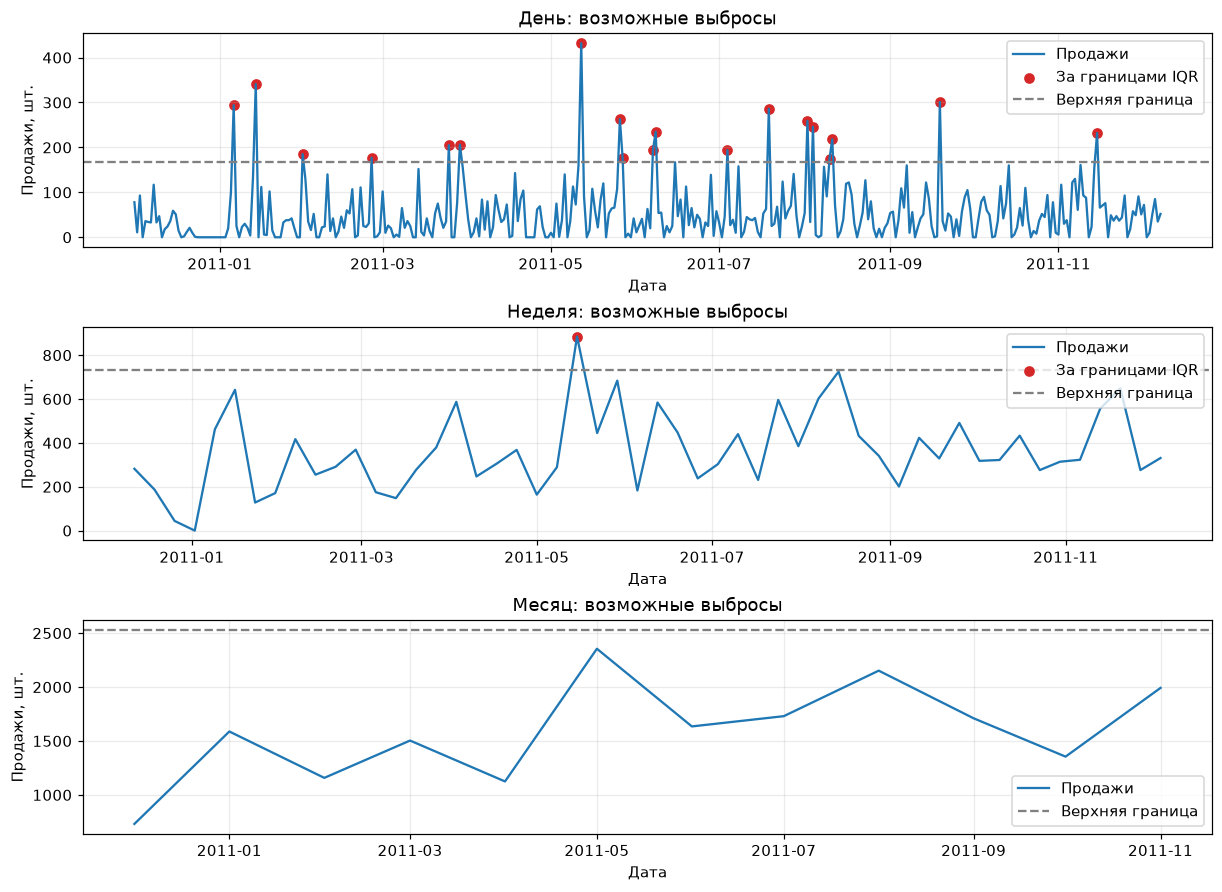

In [7]:
outlier_rows = []
for name, values in series.items():
    mask, lower, upper = iqr_outliers(values)
    outlier_rows.append(
        {"частота": name, "нижняя граница": lower, "верхняя граница": upper, "отмечено": int(mask.sum())}
    )
    if mask.any():
        display(values[mask].rename(name).to_frame())
display(pd.DataFrame(outlier_rows).set_index("частота"))
plot_quality(series)
plt.show()

In [8]:
peak_date = daily.idxmax()
peak_orders = sales.loc[
    sales.InvoiceDate.dt.normalize().eq(peak_date), ["InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice", "Country"]
]
display(peak_orders.sort_values("Quantity", ascending=False))
print("Максимум:", peak_date.date(), daily.max(), "шт.")

,InvoiceNo,InvoiceDate,Quantity,UnitPrice,Country
186860,552883,2011-05-12 10:13:00,200,1.45,Netherlands
186719,552879,2011-05-12 09:55:00,100,1.45,United Kingdom
187564,552978,2011-05-12 14:46:00,100,1.45,Germany
186610,552874,2011-05-12 09:40:00,10,1.65,Germany
186928,552890,2011-05-12 10:45:00,10,1.65,United Kingdom
188225,553017,2011-05-12 19:01:00,5,1.65,Portugal
188093,553014,2011-05-12 18:49:00,4,1.65,United Kingdom
187924,553013,2011-05-12 18:19:00,2,4.13,United Kingdom
188441,553035,2011-05-12 20:13:00,1,1.65,United Kingdom


Максимум: 2011-05-12 432.0 шт.


По IQR видны отдельные пики. В самом большом есть крупные заказы.
Явной ошибки нет, оставим как есть, иначе срежем реальные продажи.
Для разложения возьмём robust STL чтобы пики меньше влияли на тренд

## Статистики

Ещё посмотрим долю нулей, асимметрию, ACF и CV = std / mean.
Окна для среднего и разброса: 28 дней, 4 недели, 3 месяца

,День,Неделя,Месяц
count,373.000,52.000,12.000
mean,51.984,364.423,1586.250
std,61.873,178.683,457.452
min,0.000,0.000,731.000
25%,6.000,253.000,1305.750
50%,36.000,326.000,1611.500
75%,71.000,445.500,1795.500
max,432.000,885.000,2355.000
"нулей, %",20.375,1.923,0.000
CV,1.190,0.490,0.288


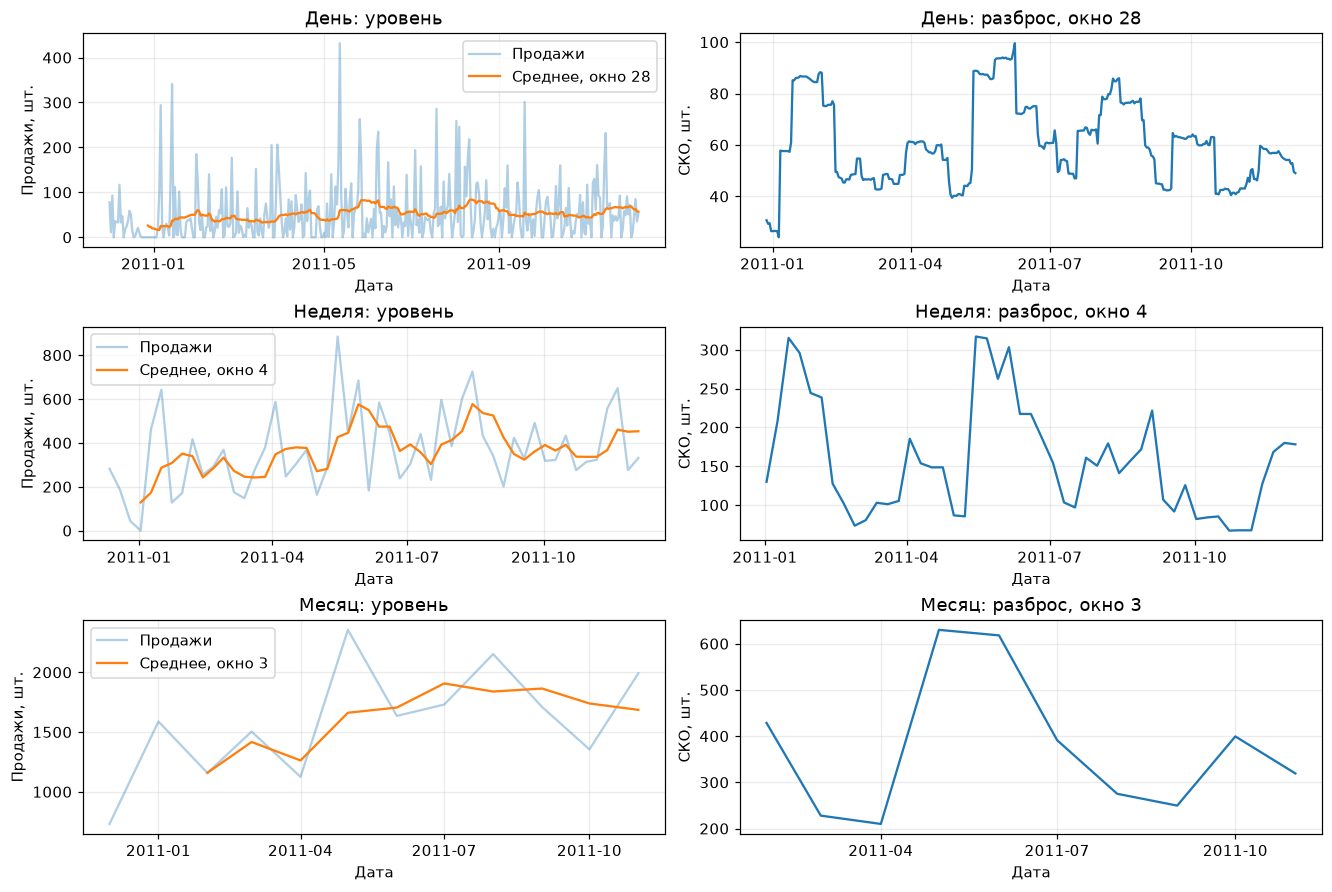

In [9]:
stats = pd.DataFrame({name: describe_series(values) for name, values in series.items()})
display(stats.round(3))
plot_rolling(series)
plt.show()

Среднее 52 шт., медиана 36, крупные заказы тянут среднее вверх.
CV на днях 1,19, на неделях 0,49, на месяцах 0,29.
Уровень в начале ниже, потом растёт и колеблется. Разброс тоже не постоянный

## Разложение

Для дней аддитивный STL, период 7 и robust=True. С нулями работает, пики оставим.
Проверим ещё ACF, спектр и дни недели. Одного графика STL для вывода мало

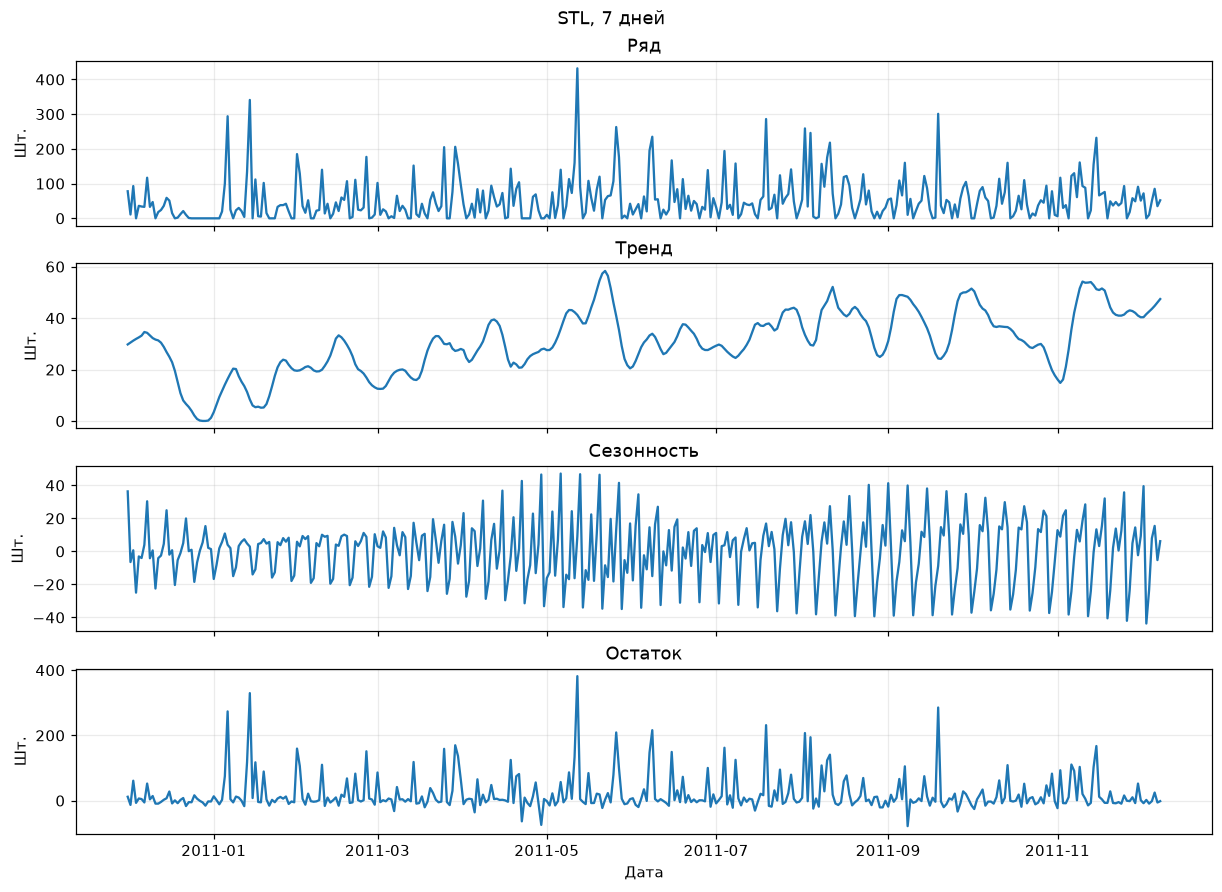

Сила сезонности: 0.151


In [10]:
components = decompose(daily, period=7)
plot_components(components, "STL, 7 дней")
plt.show()
season_strength = max(0, 1 - components["Остаток"].var() / (components["Сезонность"] + components["Остаток"]).var())
print(f"Сила сезонности: {season_strength:.3f}")

,mean,median,std
Пн,58.8,41.0,61.9
Вт,70.1,57.0,64.0
Ср,67.7,47.0,55.7
Чт,73.5,50.5,80.3
Пт,66.5,50.0,62.7
Сб,0.0,0.0,0.0
Вс,26.5,16.0,32.3


,первая половина,вторая половина
Пн,53.2,64.3
Вт,49.1,90.3
Ср,57.5,77.9
Чт,72.5,74.5
Пт,72.0,60.9
Сб,0.0,0.0
Вс,16.4,36.3


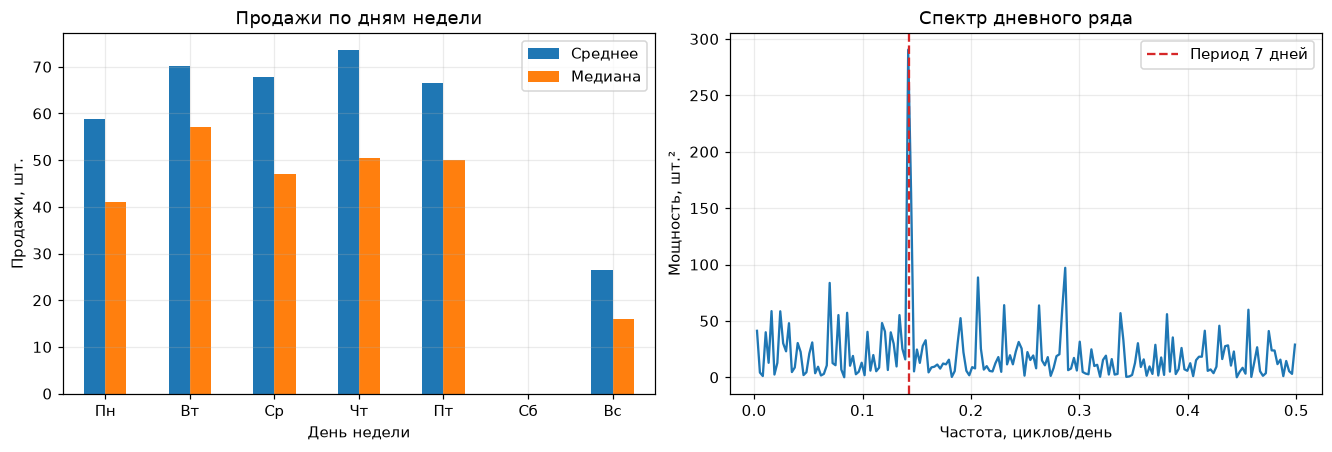

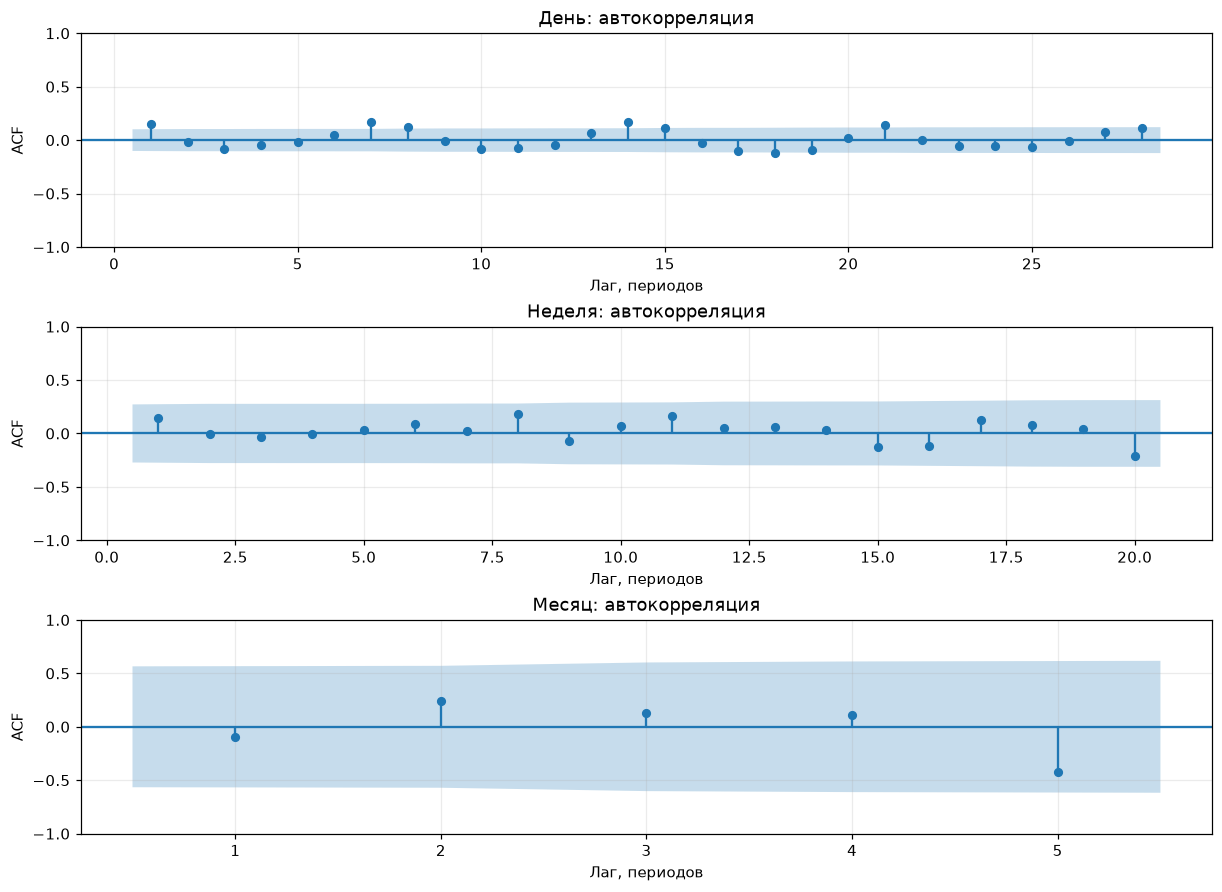

Лаги 7, 14, 21, 28


7     0.173911
14    0.172342
21    0.145927
28    0.117012
Name: корреляция, dtype: float64

In [11]:
display(weekday_profile(daily).round(1))
half = len(daily) // 2
display(
    pd.concat(
        {
            "первая половина": weekday_profile(daily.iloc[:half])["mean"],
            "вторая половина": weekday_profile(daily.iloc[half:])["mean"],
        },
        axis=1,
    ).round(1)
)
plot_weekday_and_spectrum(daily)
plt.show()
plot_seasonality(series)
plt.show()
print("Лаги 7, 14, 21, 28")
display(pd.Series({lag: daily.autocorr(lag) for lag in [7, 14, 21, 28]}, name="корреляция"))

Тренд меняется, крупные заказы остаются в остатке.
Недельный ритм есть: субботы нулевые, воскресенья слабее будней в обеих половинах ряда.
ACF на 7 и 14 около 0,17, в спектре есть пик около 1/7.
Сила сезонности 0,15, то есть недельный ритм объясняет довольно мало колебаний

В недельных суммах недельный цикл уже не виден. Для годового нужно хотя бы два года,
а тут 52 недели и 12 месяцев. Поэтому для них только тренд + остаток, без оценки сезонности.
Сгладим окнами 5 недель и 3 месяца, это не периоды сезонности

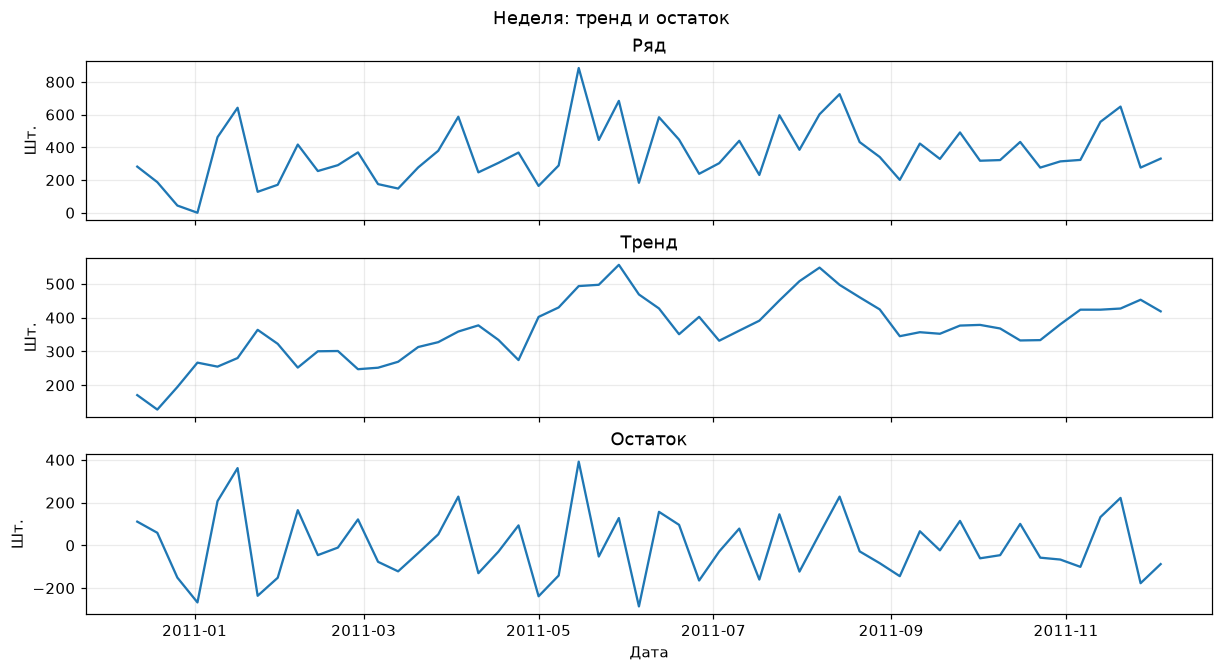

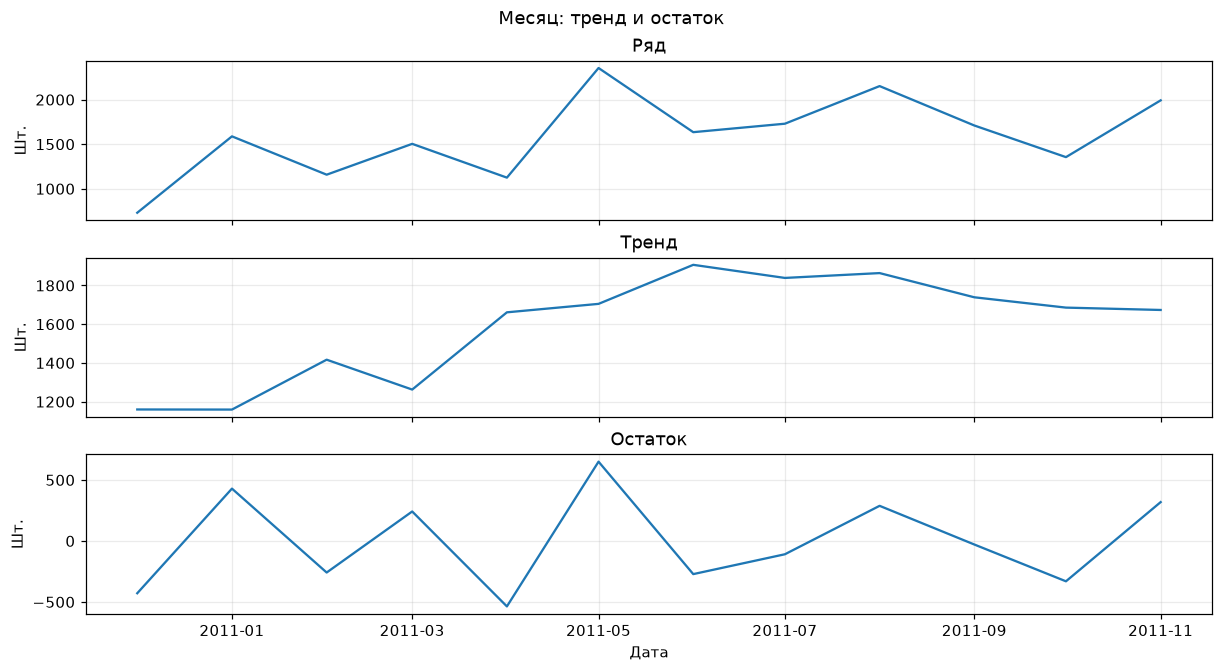

In [12]:
for name, window in [("Неделя", 5), ("Месяц", 3)]:
    parts = decompose(series[name], window=window)
    plot_components(parts, f"{name}: тренд и остаток")
    plt.show()

На обоих графиках начало ниже, к весне-лету уровень выше. В остатках отдельные пики.
Годовой цикл проверить не получилось, это не значит что его нет

## Стационарность

Порог 0,05. У ADF H0 это единичный корень, маленькое p против него.
У KPSS H0 это стационарность около постоянного уровня, маленькое p против стационарности.
В тестах константа без линейного тренда

Лаг ADF по AIC, максимум 14/4/1 для дней/недель/месяцев.
Лаги KPSS: int(4 * (n / 100)**0.25). Граничные p покажем неравенством

In [13]:
tests_before = pd.DataFrame(
    {name: stationarity(values, maxlag) for (name, values), maxlag in zip(series.items(), [14, 4, 1])}
).T
display(tests_before)

,n,ADF,p ADF,лаг ADF,KPSS,p KPSS,лаги KPSS,тесты согласны со стационарностью
День,373,-6.090064,1.04e-07,6,0.539152,0.033,5,False
Неделя,52,-6.075183,1.13e-07,0,0.455251,0.053,3,True
Месяц,12,-3.883401,0.00216,0,0.399433,0.077,2,True


Для дней ADF отвергает единичный корень, а KPSS отвергает стационарность, p около 0,033.
Гипотезы у них разные. Возьмём разность y[t] - y[t-7] из-за недельного ритма и проверим ещё раз

Недели формально проходят: у ADF маленькое p, у KPSS 0,053, но это близко к порогу.
Месяцы тоже проходят, p около 0,002 и 0,077. На 12 точках вывод слабый.
Эти два ряда пока дифференцировать не будем

,n,ADF,p ADF,лаг ADF,KPSS,p KPSS,лаги KPSS,тесты согласны со стационарностью
До,373,-6.090064,1.04e-07,6,0.539152,0.033,5,False
Разность с лагом 7,366,-6.204338,5.71e-08,14,0.01289,>= 0.100,5,True


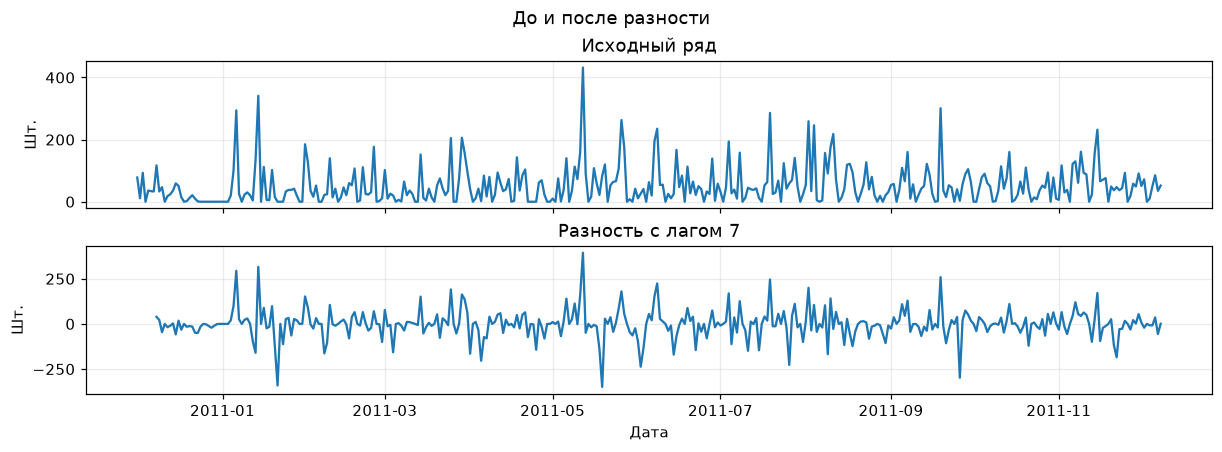

In [14]:
daily_diff = difference(daily, lag=7)
display(pd.DataFrame({"До": stationarity(daily, 14), "Разность с лагом 7": stationarity(daily_diff, 14)}).T)
plot_components(pd.DataFrame({"Исходный ряд": daily, "Разность с лагом 7": daily_diff}), "До и после разности")
plt.show()

После разности ADF p = 5,7e-8, KPSS p >= 0,1, оба согласуются со стационарностью.
Осталось 366 точек, первые 7 потерялись. Пики никуда не делись.
Это результат тестов, не гарантия постоянного распределения

Для прогноза нужны календарь и учёт крупных заказов.
Недельный ритм есть, для годового мало данных.
После разности с лагом 7 дневной ряд проходит тесты на стационарность.
Для первого прогноза выберем недели, меньше шума. Их стационарность лучше перепроверить
на более длинной истории, а месяцев для модели мало

In [15]:
save_series(aggregated, daily_diff, work / "results")